In [44]:
!pip install -q qiskit qiskit-aer

## Part 1 - Dataset Acquisition

Assumed dataset: Breast Cancer Wisconsin (569 samples; 455 train + 114 test matches your split). Label 1 = Malignant, 0 = Benign.


In [45]:
import numpy as np, pandas as pd
from sklearn.datasets import load_breast_cancer

data = pd.read_csv("breast-cancer.csv")


print("Shape:", X.shape)
print("Benign / Malignant:", np.bincount(y))

Shape: (569, 30)
Benign / Malignant: [357 212]


## Part 2 - Data Preprocessing (stratified split)


In [46]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (455, 30) Test: (114, 30)


## Part 3 - Adaptive Top-4 Feature Selection

Rank features by mutual information (training data only), then test every 4-feature combination of the top 8 with cross-validation.


In [47]:

import numpy as np, pandas as pd
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_scores = rf.feature_importances_

anova_scores, _ = f_classif(X_train, y_train)

scores_df = pd.DataFrame({
    "Mutual_Info":   mi_scores,
    "Random_Forest": rf_scores,
    "ANOVA_F":       anova_scores
}, index=X_train.columns)

ranks_df = scores_df.rank(ascending=False, method="min")


normalized = scores_df / scores_df.sum()
results_df = ranks_df.copy()
results_df["Avg_Rank"]  = ranks_df.mean(axis=1)
results_df["Avg_Score"] = normalized.mean(axis=1)
results_df = results_df.sort_values(["Avg_Rank", "Avg_Score"],
                                    ascending=[True, False])

#  Select the top 4 (same variable name the rest of the code uses)
best_4 = list(results_df.index[:4])

print("Feature ranking (top 10):")
print(results_df.head(10).round(4))
print("\nSelected top-4 features:", best_4)

Feature ranking (top 10):
                      Mutual_Info  Random_Forest  ANOVA_F  Avg_Rank  Avg_Score
worst perimeter               2.0            1.0      2.0    1.6667     0.1037
worst concave points          5.0            3.0      1.0    3.0000     0.0933
worst radius                  1.0            5.0      3.0    3.0000     0.0828
worst area                    3.0            2.0      6.0    3.6667     0.0947
mean concave points           4.0            4.0      4.0    4.0000     0.0836
mean perimeter                6.0            7.0      5.0    6.0000     0.0637
mean radius                   8.0            6.0      7.0    7.0000     0.0629
mean area                     7.0            8.0      8.0    7.6667     0.0542
mean concavity                9.0            9.0      9.0    9.0000     0.0497
worst concavity              11.0           11.0     10.0   10.6667     0.0406

Selected top-4 features: ['worst perimeter', 'worst concave points', 'worst radius', 'worst area']


## Part 4 - Classical RBF-SVM Baseline


In [48]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

X_train_4 = X_train[list(best_4)]
X_test_4  = X_test[list(best_4)]

def get_metrics(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1":        f1_score(y_true, y_pred, zero_division=0)}

classical = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
classical.fit(X_train_4, y_train)
classical_metrics = get_metrics(y_test, classical.predict(X_test_4))
print({k: round(v, 4) for k, v in classical_metrics.items()})

{'Accuracy': 0.9561, 'Precision': 1.0, 'Recall': 0.881, 'F1': 0.9367}


## Part 5 - Quantum Feature Mapping (ZZ, depths 1-3)


In [49]:
from qiskit.circuit.library import zz_feature_map
from sklearn.preprocessing import MinMaxScaler
#quantum_scaler = StandardScaler()
#X_train_scaled = quantum_scaler.fit_transform(X_train_4)
#X_test_scaled  = quantum_scaler.transform(X_test_4)


quantum_scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_scaled = quantum_scaler.fit_transform(X_train_4)
X_test_scaled  = quantum_scaler.transform(X_test_4)
print("Scaled:", X_train_scaled.shape, X_test_scaled.shape)

zz_depth_1 = zz_feature_map(feature_dimension=4, reps=1, entanglement="linear")
zz_depth_2 = zz_feature_map(feature_dimension=4, reps=2, entanglement="linear")
zz_depth_3 = zz_feature_map(feature_dimension=4, reps=3, entanglement="linear")
fmaps = {"Depth 1": zz_depth_1, "Depth 2": zz_depth_2, "Depth 3": zz_depth_3}

for name, fm in fmaps.items():
    print(name, "circuit depth:", fm.decompose().depth())

Scaled: (455, 4) (114, 4)
Depth 1 circuit depth: 11
Depth 2 circuit depth: 19
Depth 3 circuit depth: 27


## Part 6 - Quantum Kernel Construction

Kernel value = |<psi(x)|psi(y)>|^2, computed from statevectors for all three depths.


In [50]:
from qiskit.quantum_info import Statevector

def get_states(fmap, X):
    return np.array([Statevector(fmap.assign_parameters(list(x))).data for x in X])

def ideal_kernel(fmap, XA, XB=None):
    SA = get_states(fmap, XA)
    SB = SA if XB is None else get_states(fmap, XB)
    return np.abs(SA.conj() @ SB.T) ** 2

kernels = {}
for name, fm in fmaps.items():
    K_tr = ideal_kernel(fm, X_train_scaled)
    K_te = ideal_kernel(fm, X_test_scaled, X_train_scaled)
    kernels[name] = (K_tr, K_te)
    print(name, "| train kernel:", K_tr.shape, "| test kernel:", K_te.shape)

Depth 1 | train kernel: (455, 455) | test kernel: (114, 455)
Depth 2 | train kernel: (455, 455) | test kernel: (114, 455)
Depth 3 | train kernel: (455, 455) | test kernel: (114, 455)


## Part 7 - Quantum Kernel Classification (QSVC equivalent)


                   Accuracy  Precision  Recall     F1
Model                                                
Classical RBF-SVM     95.61      100.0   88.10  93.67
Depth 1               95.61      100.0   88.10  93.67
Depth 2               92.98      100.0   80.95  89.47
Depth 3               90.35      100.0   73.81  84.93


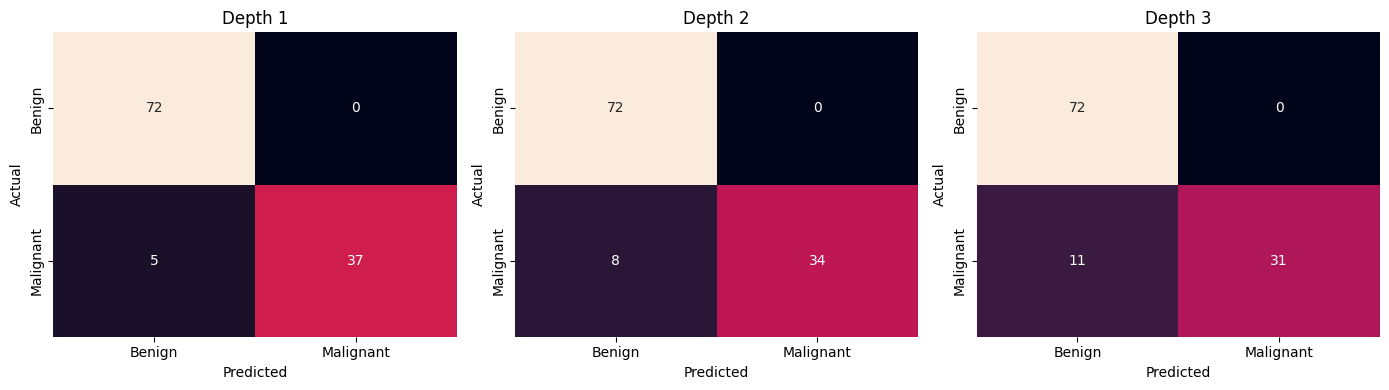

In [51]:
import matplotlib.pyplot as plt, seaborn as sns

rows, y_preds = [], {}
for name, (K_tr, K_te) in kernels.items():
    model = SVC(kernel="precomputed")
    model.fit(K_tr, y_train)
    y_pred = model.predict(K_te)
    y_preds[name] = y_pred
    rows.append({"Model": name, **get_metrics(y_test, y_pred)})

rows.insert(0, {"Model": "Classical RBF-SVM", **classical_metrics})
ideal_results = pd.DataFrame(rows).set_index("Model")
print((ideal_results * 100).round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, yp) in zip(axes, y_preds.items()):
    sns.heatmap(confusion_matrix(y_test, yp), annot=True, fmt="d", cbar=False, ax=ax,
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## Part 8 - Circuit Configuration Analysis

Depth (1-3) x entanglement (linear / full). Selection uses 5-fold cross-validation on the training set only; test F1 is reported alongside.


In [52]:
skf = StratifiedKFold(5, shuffle=True, random_state=42)
y_tr = np.asarray(y_train)
rows = []
for ent in ["linear", "full"]:
    for reps in [1, 2, 3]:
        fm = zz_feature_map(feature_dimension=4, reps=reps, entanglement=ent)
        K_tr = ideal_kernel(fm, X_train_scaled)
        K_te = ideal_kernel(fm, X_test_scaled, X_train_scaled)
        cv_f1 = []
        for a, b in skf.split(K_tr, y_tr):
            m = SVC(kernel="precomputed").fit(K_tr[np.ix_(a, a)], y_tr[a])
            cv_f1.append(f1_score(y_tr[b], m.predict(K_tr[np.ix_(b, a)])))
        m = SVC(kernel="precomputed").fit(K_tr, y_tr)
        off_diag = K_tr[~np.eye(len(K_tr), dtype=bool)]
        rows.append({"Entanglement": ent, "Depth": reps,
                     "CV F1": np.mean(cv_f1),
                     "Test F1": f1_score(y_test, m.predict(K_te)),
                     "Kernel spread (std)": off_diag.std()})

config_results = pd.DataFrame(rows)
print(config_results.round(4).to_string(index=False))

Entanglement  Depth  CV F1  Test F1  Kernel spread (std)
      linear      1 0.9164   0.9367               0.1780
      linear      2 0.8777   0.8947               0.1611
      linear      3 0.8358   0.8493               0.1480
        full      1 0.9087   0.9231               0.1609
        full      2 0.8532   0.8718               0.1325
        full      3 0.7580   0.7733               0.1115


## Part 9 - Noise-Aware Evaluation

Uses a **separate stratified subset** (`*_noise` variables), so Parts 1-8 are untouched.

Speed knobs: lower `N_NOISE_TRAIN` or `SHOTS` if it is still too slow. Every kernel entry needs its own noisy circuit run, so cost grows with N_TRAIN squared.


In [53]:
from qiskit import transpile
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

N_NOISE_TRAIN, N_NOISE_TEST, SHOTS = 60, 30, 256

X_train_noise, _, y_train_noise, _ = train_test_split(
    X_train_scaled, np.asarray(y_train), train_size=N_NOISE_TRAIN,
    stratify=y_train, random_state=42)
X_test_noise, _, y_test_noise, _ = train_test_split(
    X_test_scaled, np.asarray(y_test), train_size=N_NOISE_TEST,
    stratify=y_test, random_state=42)
print("Noise subset:", len(X_train_noise), "train /", len(X_test_noise), "test")
print("Class counts train:", np.bincount(y_train_noise), "test:", np.bincount(y_test_noise))

# Noise model: 1% 1-qubit, 2% 2-qubit depolarizing, 2% readout error
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.01, 1), ["u"])
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.02, 2), ["cx"])
noise_model.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.02, 0.98]]))
backend = AerSimulator(noise_model=noise_model)

def make_template(fmap):
    px, py = ParameterVector("px", 4), ParameterVector("py", 4)
    fx = fmap.assign_parameters(dict(zip(fmap.parameters, px)))
    fy = fmap.assign_parameters(dict(zip(fmap.parameters, py)))
    qc = fx.compose(fy.inverse())
    qc.measure_all()
    return transpile(qc, basis_gates=["u", "cx"], optimization_level=1), px, py

def run_pairs(tpl, px, py, pairs, XA, XB):
    circs = [tpl.assign_parameters({**dict(zip(px, map(float, XA[i]))),
                                    **dict(zip(py, map(float, XB[j])))})
             for i, j in pairs]
    fids = []
    for s in range(0, len(circs), 500):
        chunk = circs[s:s + 500]
        res = backend.run(chunk, shots=SHOTS).result()
        fids += [res.get_counts(k).get("0000", 0) / SHOTS for k in range(len(chunk))]
    return np.array(fids)

def noisy_kernel(fmap, XA, XB=None):
    tpl, px, py = make_template(fmap)
    if XB is None:
        n = len(XA)
        pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
        f = run_pairs(tpl, px, py, pairs, XA, XA)
        K = np.eye(n)
        for (i, j), v in zip(pairs, f):
            K[i, j] = K[j, i] = v
        return K
    pairs = [(i, j) for i in range(len(XA)) for j in range(len(XB))]
    return run_pairs(tpl, px, py, pairs, XA, XB).reshape(len(XA), len(XB))

import time
rows = []
for name, fm in fmaps.items():
    t0 = time.time()
    K_tr = noisy_kernel(fm, X_train_noise)
    K_te = noisy_kernel(fm, X_test_noise, X_train_noise)
    noisy_pred = SVC(kernel="precomputed").fit(K_tr, y_train_noise).predict(K_te)

    Ki_tr = ideal_kernel(fm, X_train_noise)
    Ki_te = ideal_kernel(fm, X_test_noise, X_train_noise)
    ideal_pred = SVC(kernel="precomputed").fit(Ki_tr, y_train_noise).predict(Ki_te)

    rows.append({"Depth": name, "Setting": "Ideal (subset)", **get_metrics(y_test_noise, ideal_pred)})
    rows.append({"Depth": name, "Setting": "Noisy", **get_metrics(y_test_noise, noisy_pred)})
    print(f"{name} done in {time.time() - t0:.0f}s")

noise_results = pd.DataFrame(rows)
print((noise_results.set_index(["Depth", "Setting"]) * 100).round(2))

Noise subset: 60 train / 30 test
Class counts train: [38 22] test: [19 11]
Depth 1 done in 21s
Depth 2 done in 38s
Depth 3 done in 29s
                        Accuracy  Precision  Recall     F1
Depth   Setting                                           
Depth 1 Ideal (subset)     83.33      100.0   54.55  70.59
        Noisy              86.67      100.0   63.64  77.78
Depth 2 Ideal (subset)     80.00      100.0   45.45  62.50
        Noisy              76.67      100.0   36.36  53.33
Depth 3 Ideal (subset)     83.33      100.0   54.55  70.59
        Noisy              70.00      100.0   18.18  30.77


**Report note:** the noise results use a small fixed subset (stratified, 60 train + 30 test) to keep simulation cost manageable. Present them as a _noise sensitivity experiment_. Your main classification result comes from the full-dataset ideal results in Part 7.


Part 10 - Classical vs Quantum Comparison
Both sides get the same fair treatment: hyperparameters are tuned with 5-fold cross-validation on the training set only, then each model is scored once on the test set.

Classical RBF-SVM: tunes C and gamma.
Quantum kernel SVM: tunes depth, feature scaling (kernel bandwidth) and C.
Nothing here uses the test set to choose a model, and results are reported as they come out.


In [54]:
from sklearn.model_selection import GridSearchCV

skf = StratifiedKFold(5, shuffle=True, random_state=42)
y_tr = np.asarray(y_train)


grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1, 1]},
    cv=skf, scoring="f1")
grid.fit(X_train_4, y_train)
classical_tuned = grid.best_estimator_
classical_tuned_pred = classical_tuned.predict(X_test_4)
classical_tuned_metrics = get_metrics(y_test, classical_tuned_pred)
classical_cv_f1 = grid.best_score_
print("Classical best params:", grid.best_params_, "| CV F1:", round(classical_cv_f1, 4))


alphas, Cs = [0.25, 0.5, 1.0], [0.1, 1, 10, 100]
search = []
for name, fm in fmaps.items():
    for a in alphas:
        K_tr = ideal_kernel(fm, a * X_train_scaled)
        for C in Cs:
            f1s = []
            for tr, va in skf.split(K_tr, y_tr):
                m = SVC(kernel="precomputed", C=C).fit(K_tr[np.ix_(tr, tr)], y_tr[tr])
                f1s.append(f1_score(y_tr[va], m.predict(K_tr[np.ix_(va, tr)])))
            search.append({"Depth": name, "Scale": a, "C": C, "CV_F1": np.mean(f1s)})

quantum_search = pd.DataFrame(search).sort_values("CV_F1", ascending=False).reset_index(drop=True)
bq = quantum_search.iloc[0]
print("Quantum best config:", dict(bq), )

fm_best = fmaps[bq["Depth"]]
K_tr_best = ideal_kernel(fm_best, bq["Scale"] * X_train_scaled)
K_te_best = ideal_kernel(fm_best, bq["Scale"] * X_test_scaled, bq["Scale"] * X_train_scaled)
quantum_tuned_model = SVC(kernel="precomputed", C=bq["C"]).fit(K_tr_best, y_tr)
quantum_tuned_pred = quantum_tuned_model.predict(K_te_best)
quantum_tuned_metrics = get_metrics(y_test, quantum_tuned_pred)
quantum_cv_f1 = bq["CV_F1"]

# ---- Comparison table ----
comparison = {"Classical RBF-SVM (default)": classical_metrics,
              "Classical RBF-SVM (tuned)":   classical_tuned_metrics}
for name in fmaps:
    comparison[f"Quantum {name} (default)"] = ideal_results.loc[name].to_dict()
comparison[f"Quantum tuned ({bq['Depth']})"] = quantum_tuned_metrics

comparison_df = pd.DataFrame(comparison).T
print("\n=== TEST-SET COMPARISON (%) ===")
print((comparison_df * 100).round(2))

print("\nCross-validated F1 (training only): classical =", round(classical_cv_f1, 4),
      "| quantum =", round(quantum_cv_f1, 4))
print("Quantum tuned F1 > classical tuned F1 on test set?",
      quantum_tuned_metrics["F1"] > classical_tuned_metrics["F1"])

Classical best params: {'svc__C': 10, 'svc__gamma': 0.01} | CV F1: 0.9397
Quantum best config: {'Depth': 'Depth 2', 'Scale': np.float64(0.5), 'C': np.float64(1.0), 'CV_F1': np.float64(0.93647070746815)}

=== TEST-SET COMPARISON (%) ===
                             Accuracy  Precision  Recall     F1
Classical RBF-SVM (default)     95.61      100.0   88.10  93.67
Classical RBF-SVM (tuned)       95.61      100.0   88.10  93.67
Quantum Depth 1 (default)       95.61      100.0   88.10  93.67
Quantum Depth 2 (default)       92.98      100.0   80.95  89.47
Quantum Depth 3 (default)       90.35      100.0   73.81  84.93
Quantum tuned (Depth 2)         95.61      100.0   88.10  93.67

Cross-validated F1 (training only): classical = 0.9397 | quantum = 0.9365
Quantum tuned F1 > classical tuned F1 on test set? False


**Final Evaluation**


FINAL QUANTUM MODEL: {'Depth': 'Depth 2', 'Scale': np.float64(0.5), 'C': np.float64(1.0), 'CV_F1': np.float64(0.93647070746815)}

--- Classification report: QUANTUM ---
              precision    recall  f1-score   support

      Benign     0.9351    1.0000    0.9664        72
   Malignant     1.0000    0.8810    0.9367        42

    accuracy                         0.9561       114
   macro avg     0.9675    0.9405    0.9516       114
weighted avg     0.9590    0.9561    0.9555       114

--- Classification report: CLASSICAL (tuned) ---
              precision    recall  f1-score   support

      Benign     0.9351    1.0000    0.9664        72
   Malignant     1.0000    0.8810    0.9367        42

    accuracy                         0.9561       114
   macro avg     0.9675    0.9405    0.9516       114
weighted avg     0.9590    0.9561    0.9555       114



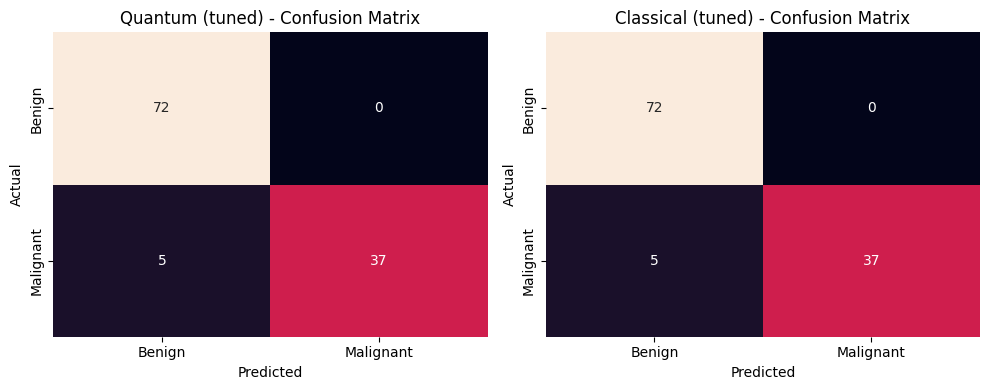

                   Accuracy  Precision  Recall     F1
Quantum (final)       95.61      100.0    88.1  93.67
Classical (tuned)     95.61      100.0    88.1  93.67


In [55]:
from sklearn.metrics import classification_report

labels = ["Benign", "Malignant"]
print("FINAL QUANTUM MODEL:", dict(bq))
print("\n--- Classification report: QUANTUM ---")
print(classification_report(y_test, quantum_tuned_pred, target_names=labels, digits=4))
print("--- Classification report: CLASSICAL (tuned) ---")
print(classification_report(y_test, classical_tuned_pred, target_names=labels, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, title, yp in zip(axes, ["Quantum (tuned)", "Classical (tuned)"],
                         [quantum_tuned_pred, classical_tuned_pred]):
    sns.heatmap(confusion_matrix(y_test, yp), annot=True, fmt="d", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(f"{title} - Confusion Matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

final_metrics = pd.DataFrame({"Quantum (final)": quantum_tuned_metrics,
                              "Classical (tuned)": classical_tuned_metrics}).T
print((final_metrics * 100).round(2))

## ** Results & Visualization**


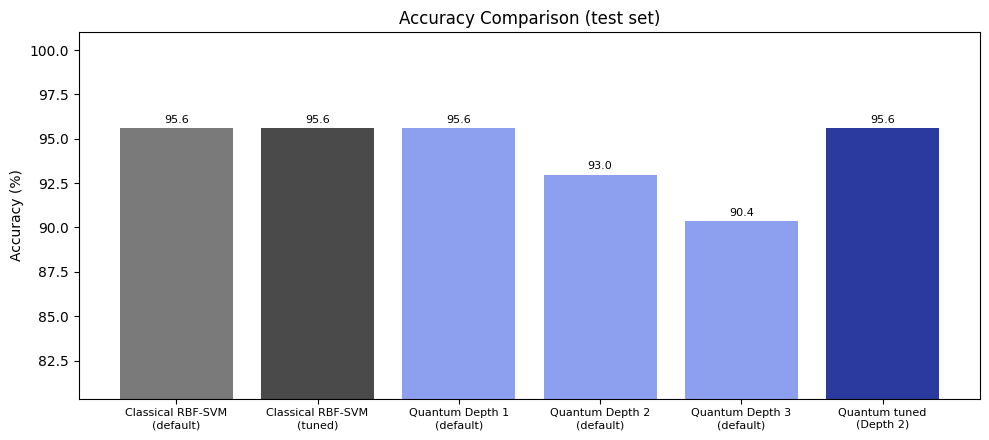

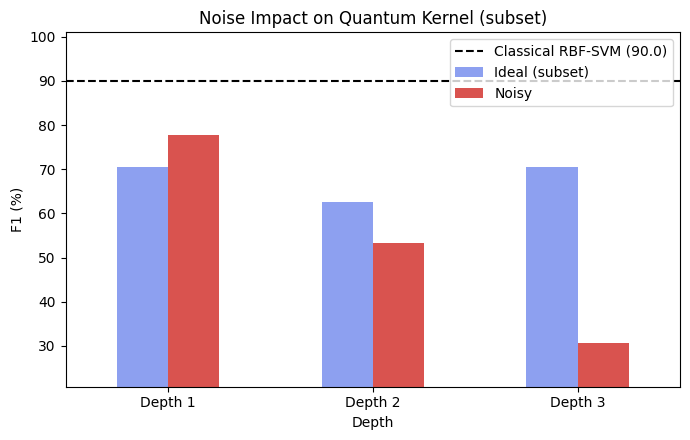

Setting  Ideal (subset)  Noisy
Depth                         
Depth 1           70.59  77.78
Depth 2           62.50  53.33
Depth 3           70.59  30.77


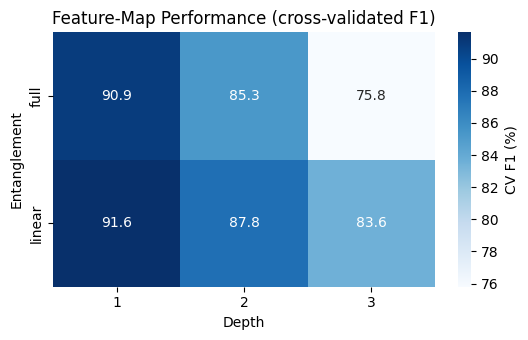

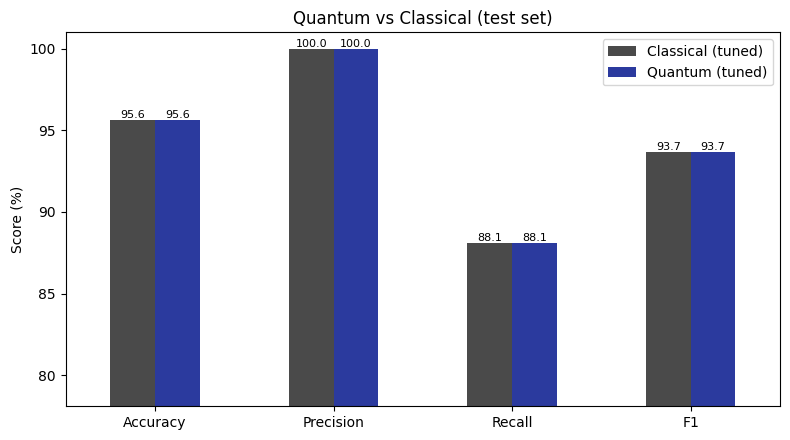

           Classical (tuned)  Quantum (tuned)
Accuracy               95.61            95.61
Precision             100.00           100.00
Recall                 88.10            88.10
F1                     93.67            93.67


In [56]:
# ---- 1. Accuracy comparison ----
plt.figure(figsize=(10, 4.5))
acc = comparison_df["Accuracy"] * 100
bars = plt.bar(range(len(acc)), acc, color=["#7a7a7a", "#4a4a4a"] + ["#8da0f0"] * 3 + ["#2b3a9e"])
plt.xticks(range(len(acc)), [i.replace(" (", "\n(") for i in acc.index], fontsize=8)
plt.ylim(max(0, acc.min() - 10), 101); plt.ylabel("Accuracy (%)")
for b, v in zip(bars, acc): plt.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f}", ha="center", fontsize=8)
plt.title("Accuracy Comparison (test set)"); plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=150); plt.show()

# ---- 2. Noise impact (same stratified subset for every bar) ----
cl_sub = make_pipeline(StandardScaler(), SVC(kernel="rbf")).fit(X_train_noise, y_train_noise)
cl_sub_f1 = f1_score(y_test_noise, cl_sub.predict(X_test_noise), zero_division=0)

piv = noise_results.pivot(index="Depth", columns="Setting", values="F1") * 100
ax = piv[["Ideal (subset)", "Noisy"]].plot(kind="bar", figsize=(7, 4.5), color=["#8da0f0", "#d9534f"], rot=0)
ax.axhline(cl_sub_f1 * 100, color="black", ls="--", label=f"Classical RBF-SVM ({cl_sub_f1*100:.1f})")
ax.set_ylabel("F1 (%)"); ax.set_title("Noise Impact on Quantum Kernel (subset)")
ax.set_ylim(max(0, piv.values.min() - 10), 101); ax.legend()
plt.tight_layout(); plt.savefig("noise_impact.png", dpi=150); plt.show()
print((piv.round(2)))

# ---- 3. Feature-map performance (Part 8) ----
cfg = config_results.pivot(index="Entanglement", columns="Depth", values="CV F1") * 100
plt.figure(figsize=(5.5, 3.5))
sns.heatmap(cfg, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "CV F1 (%)"})
plt.title("Feature-Map Performance (cross-validated F1)"); plt.tight_layout()
plt.savefig("feature_map_performance.png", dpi=150); plt.show()

# ---- 4. Quantum vs classical, all metrics ----
qc_df = pd.DataFrame({"Classical (tuned)": classical_tuned_metrics,
                      "Quantum (tuned)": quantum_tuned_metrics}) * 100
ax = qc_df.plot(kind="bar", figsize=(8, 4.5), color=["#4a4a4a", "#2b3a9e"], rot=0)
ax.set_ylabel("Score (%)"); ax.set_ylim(max(0, qc_df.values.min() - 10), 101)
ax.set_title("Quantum vs Classical (test set)")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.tight_layout(); plt.savefig("quantum_vs_classical.png", dpi=150); plt.show()
print(qc_df.round(2))